# 82514 · Sesión S11 — El jacobiano: cinemática diferencial del 2R al 6R

**Bloque 4** · lunes 26 de octubre de 2026 · 2 h  ·  IQS Universitat Ramon Llull

**Qué hace este cuaderno.** Deduce a mano el jacobiano geométrico del 2R plano del bloque (a1 = 0,35 m, a2 = 0,2 m) y reproduce el ejemplo de clase en la postura q = (1,0°; 74,5°); lo valida por diferencias finitas, lo compara columna a columna con el jacob0 de la Robotics Toolbox y lo usa en las dos direcciones: de las velocidades articulares a la velocidad de la mano, y de la velocidad de la mano a las velocidades articulares (control de movimiento de velocidad resuelta).

**Se apoya en:** Lynch y Park (2017), cap. 5 — definición de J(q) y su lectura como sensibilidad lineal (p. 171), interpretación columna a columna en el 2R (pp. 171-173), alineación de columnas y pérdida de direcciones (p. 173) y singularidad cinemática frente a representacional (p. 192); Corke (2023), cap. 8 — jacob0 y la velocidad espacial en el marco del mundo (pp. 310-311), jacobiano en el marco del efector (p. 311), jacobiano analítico y singularidad representacional (p. 312), control de movimiento de velocidad resuelta (p. 313), deriva de integración y lazo cerrado (pp. 313-314) y jacobianos no cuadrados o singulares (p. 315).

**Cómo usarlo en clase.** Sigue el guion de la sesión S11 en las diapositivas del bloque 4. Ejecuta la celda de instalación una sola vez al empezar; en Colab tarda varios minutos. Las celdas marcadas **Ejercicio** son para que los trabajen los estudiantes: las soluciones están al final del cuaderno.

---

In [1]:
# Ejecutar una sola vez. En Colab tarda varios minutos.
import importlib, subprocess, sys

def asegurar(mods):
    faltan = []
    for pip_name, import_name in mods:
        try:
            importlib.import_module(import_name)
        except ImportError:
            faltan.append(pip_name)
    if faltan:
        print('Instalando:', ' '.join(faltan))
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + faltan, check=False)
    else:
        print('Todo instalado ya.')

asegurar([('numpy', 'numpy'), ('matplotlib', 'matplotlib'), ('spatialmath-python', 'spatialmath'), ('roboticstoolbox-python==1.4.4', 'roboticstoolbox')])

import numpy as np
import matplotlib.pyplot as plt
import roboticstoolbox as rtb
from spatialmath import SE3

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.figsize'] = (9, 3.4)
plt.rcParams['axes.grid'] = True
IQS_AZUL, IQS_VERDE = '#1B2A80', '#1FA355'
print('roboticstoolbox', rtb.__version__, '- listo.')

Instalando: spatialmath-python roboticstoolbox-python==1.4.4
roboticstoolbox 1.4.4 - listo.


> **Aviso para Colab.** `roboticstoolbox-python` **tarda varios minutos** en instalarse la primera vez: lanza la celda de instalación nada más abrir el cuaderno. Las secciones 1 y 2 no usan la toolbox, así que se pueden ir leyendo mientras termina. La celda instala la versión 1.4.4 de la toolbox y la imprime al terminar. Como siempre, **sin `robot.plot()` ni `robot.teach()`**.
>
> **En clase:** las cuatro secciones y el ejercicio 2. Los ejercicios 1 y 3, en casa: el 1 está dentro de la sección 3, así que en clase sáltalo y sigue con la sección 4.

## 1. El jacobiano del 2R, deducido a mano

La cinemática de velocidad pregunta cómo se traducen las velocidades articulares en velocidad del efector, la mano. La respuesta es la derivada de la cinemática directa: si `x = f(q)`, la regla de la cadena da

`ẋ = (∂f/∂q)·q̇ = J(q)·q̇`

«donde J(q), perteneciente a R^(m x n), se llama el jacobiano. La matriz jacobiana representa la sensibilidad lineal de la velocidad del efector ẋ a la velocidad articular q̇, y es función de las variables articulares q» (Lynch y Park, 2017, p. 171).

Usamos el 2R plano de todo el bloque, el de la directa de S9 y la inversa de S10: `a1 = 0.35 m` y `a2 = 0.2 m`. Su directa es

```
x = a1·cos(q1) + a2·cos(q1+q2)
y = a1·sin(q1) + a2·sin(q1+q2)
```

y derivar con la regla de la cadena son cuatro líneas. Ordenando por `q̇1` y `q̇2` sale

```
        ⎡ −a1·sin(q1) − a2·sin(q1+q2)   −a2·sin(q1+q2) ⎤
J(q) =  ⎢                                              ⎥
        ⎣  a1·cos(q1) + a2·cos(q1+q2)    a2·cos(q1+q2) ⎦
```

**La lectura que da intuición física es columna a columna:** la columna i de J es la velocidad que adquiere el efector cuando la articulación i gira a velocidad unidad con las demás quietas (Lynch y Park, 2017, pp. 171-173). En el 2R, la primera columna es `(−y, x)`: si solo gira el hombro, la mano da vueltas alrededor de la base, perpendicular a la recta base-mano y a `r` m/s por cada rad/s, siendo `r` la distancia de la base a la mano. La segunda mide siempre `a2`: si solo gira el codo, la mano da vueltas alrededor del codo.

La celda reproduce el ejemplo resuelto en clase: el 2R en la postura codo abajo de S10, `q = (1.04°, 74.46°)`, con la mano en `P = (0.4, 0.2) m`.

In [2]:
A1, A2 = 0.35, 0.2        # el 2R del bloque: longitudes de los eslabones (m)

def fk_2r(q, a1=A1, a2=A2):
    q1, q2 = q
    return np.array([a1*np.cos(q1) + a2*np.cos(q1+q2),
                     a1*np.sin(q1) + a2*np.sin(q1+q2)])

def jac_2r(q, a1=A1, a2=A2):
    """Jacobiano geometrico (parte traslacional) del 2R plano, deducido a mano."""
    q1, q2 = q
    s1, c1 = np.sin(q1), np.cos(q1)
    s12, c12 = np.sin(q1 + q2), np.cos(q1 + q2)
    return np.array([[-a1*s1 - a2*s12, -a2*s12],
                     [ a1*c1 + a2*c12,  a2*c12]])

q0 = np.deg2rad([1.04, 74.46])     # la postura codo abajo del ejemplo de clase
P0 = fk_2r(q0)
J = jac_2r(q0)
print('q = (1.04°, 74.46°)  ->  la mano en P =', P0.round(4), 'm')
print('J =\n', J)
print('\ncolumna 1 (solo se mueve el hombro):', J[:, 0].round(4),
      '  es (-y, x) =', np.array([-P0[1], P0[0]]).round(4))
print('   modulo', round(float(np.linalg.norm(J[:, 0])), 4),
      '= r, la distancia de la base a la mano')
print('columna 2 (solo se mueve el codo)  :', J[:, 1].round(4),
      '  modulo', round(float(np.linalg.norm(J[:, 1])), 4), '= a2')
print(f'\ndet J = {np.linalg.det(J):.4f} m²  = a1·a2·sin(q2) = {A1*A2*np.sin(q0[1]):.4f};'
      f'  su maximo, con sin(q2) = 1: a1·a2 = {A1*A2:.2f} m²')

q = (1.04°, 74.46°)  ->  la mano en P = [0.4 0.2] m
J =
 [[-0.2    -0.1936]
 [ 0.4     0.0501]]

columna 1 (solo se mueve el hombro): [-0.2  0.4]   es (-y, x) = [-0.2  0.4]
   modulo 0.4472 = r, la distancia de la base a la mano
columna 2 (solo se mueve el codo)  : [-0.1936  0.0501]   modulo 0.2 = a2

det J = 0.0674 m²  = a1·a2·sin(q2) = 0.0674;  su maximo, con sin(q2) = 1: a1·a2 = 0.07 m²


Dibujar las dos columnas sobre el brazo, en dos posturas distintas, es lo que hace visible el concepto: la del ejemplo y otra con el brazo casi estirado (`q2 = 10°`). Las flechas van a media escala, como en las diapositivas. Y de paso adelanta la observación que estructura la segunda hora: **cuando las dos columnas se alinean, hay direcciones en las que el efector no puede moverse** (Lynch y Park, 2017, p. 172).

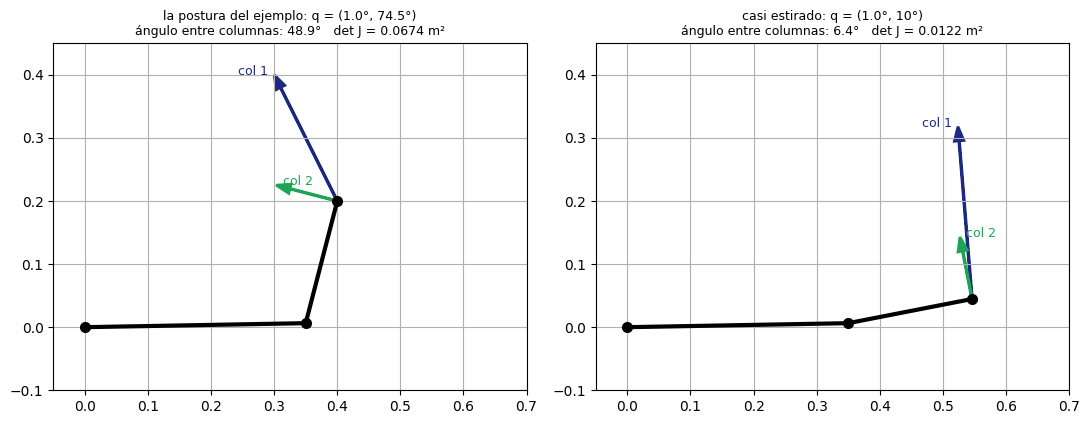

In [3]:
def puntos_2r(q, a1=A1, a2=A2):
    q1, q2 = q
    p0 = np.zeros(2)
    p1 = p0 + a1*np.array([np.cos(q1), np.sin(q1)])
    p2 = p1 + a2*np.array([np.cos(q1+q2), np.sin(q1+q2)])
    return np.vstack([p0, p1, p2])

posturas = [(q0,                       'la postura del ejemplo: q = (1.0°, 74.5°)'),
            (np.deg2rad([1.04, 10.0]), 'casi estirado: q = (1.0°, 10°)')]
ESCALA = 0.5          # flechas a media escala: 1 rad/s se dibuja como medio segundo de movimiento

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (q, titulo) in zip(axes, posturas):
    P = puntos_2r(q); Jq = jac_2r(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, ms=7, color='black', label='brazo')
    for k, (col, color) in enumerate(zip(Jq.T, [IQS_AZUL, IQS_VERDE])):
        f = ESCALA*col
        ax.arrow(P[-1, 0], P[-1, 1], f[0], f[1], head_width=0.015,
                 color=color, length_includes_head=True, lw=2)
        ax.text(P[-1, 0] + f[0] + (-0.01 if k == 0 else 0.01), P[-1, 1] + f[1],
                f'col {k+1}', color=color, fontsize=9, ha='right' if k == 0 else 'left')
    ang = np.rad2deg(np.arccos(np.clip(
        Jq[:, 0] @ Jq[:, 1] / (np.linalg.norm(Jq[:, 0])*np.linalg.norm(Jq[:, 1])), -1, 1)))
    ax.set_title(f'{titulo}\nángulo entre columnas: {ang:.1f}°   det J = {np.linalg.det(Jq):.4f} m²',
                 fontsize=9)
    ax.set_aspect('equal'); ax.set_xlim(-0.05, 0.7); ax.set_ylim(-0.1, 0.45)
plt.tight_layout(); plt.show()

## 2. Validación por diferencias finitas

Antes de fiarse de una derivada escrita a mano hay que comprobarla. La forma barata y definitiva es la diferencia finita centrada: girar cada articulación un `h` pequeño en los dos sentidos, ver con la directa dónde queda la mano, restar y dividir entre `2h`. Lo que sale es esa columna.

`∂f/∂q_i ≈ (f(q + h·e_i) − f(q − h·e_i)) / (2h)`

Solo hace falta la directa, así que vale para cualquier cinemática, por complicada que sea (la de vuestro robot también), y es la comprobación que conviene hacer **siempre** que uno derive un jacobiano nuevo. La primera celda repite la cuenta de clase: `h = 0.001` rad en la postura del ejemplo.

In [4]:
def jac_diferencias(f, q, h=1e-6):
    """Jacobiano numerico por diferencias finitas centradas."""
    q = np.asarray(q, float)
    cols = []
    for i in range(len(q)):
        e = np.zeros_like(q); e[i] = h
        cols.append((f(q + e) - f(q - e)) / (2*h))
    return np.column_stack(cols)

h = 1e-3                                   # una milesima de radian, como en clase
for i, quien in enumerate(['el hombro', 'el codo']):
    e = np.zeros(2); e[i] = h
    p_mas, p_menos = fk_2r(q0 + e), fk_2r(q0 - e)
    d = p_mas - p_menos
    print(f'Columna {i+1}, girando {quien} ±h:')
    print(f'   p(+h) = ({p_mas[0]:.4f}, {p_mas[1]:.4f})   p(-h) = ({p_menos[0]:.4f}, {p_menos[1]:.4f})')
    print(f'   diferencia = ({d[0]:.7f}, {d[1]:.7f})   entre 2h = ({d[0]/(2*h):.4f}, {d[1]/(2*h):.4f})')

J_num = jac_diferencias(fk_2r, q0, h=1e-3)
print('\nJ deducido a mano =\n', J)
print('J por diferencias finitas, h = 0.001 =\n', J_num)
print(f'\nDiferencia maxima: {np.abs(J - J_num).max():.1e}  (menos de una diezmillonesima)')

Columna 1, girando el hombro ±h:
   p(+h) = (0.3998, 0.2004)   p(-h) = (0.4002, 0.1996)
   diferencia = (-0.0004000, 0.0008000)   entre 2h = (-0.2000, 0.4000)
Columna 2, girando el codo ±h:
   p(+h) = (0.3998, 0.2000)   p(-h) = (0.4002, 0.1999)
   diferencia = (-0.0003873, 0.0001002)   entre 2h = (-0.1936, 0.0501)

J deducido a mano =
 [[-0.2    -0.1936]
 [ 0.4     0.0501]]
J por diferencias finitas, h = 0.001 =
 [[-0.2    -0.1936]
 [ 0.4     0.0501]]

Diferencia maxima: 6.7e-08  (menos de una diezmillonesima)


También merece la pena mirar cómo se comporta el error con `h`. Baja como `h²` mientras domina el error de truncamiento: cada vez que `h` se divide entre 10, el error se divide entre 100. Y vuelve a subir cuando domina el redondeo, porque se restan dos números casi iguales.

In [5]:
print('Barrido del paso h, en la postura del ejemplo:')
print(f"{'h':>10} {'error maximo':>15}")
errores = {}
for hh in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-8, 1e-10, 1e-12]:
    errores[hh] = np.abs(J - jac_diferencias(fk_2r, q0, hh)).max()
    print(f'{hh:>10.0e} {errores[hh]:>15.3e}')
h_mejor = min(errores, key=errores.get)
print(f'\nEl minimo esta en h = {h_mejor:.0e}: por debajo, el redondeo se come la señal.')
print('jac_diferencias usa h = 1e-6 por defecto, dentro de la zona buena.')

Barrido del paso h, en la postura del ejemplo:
         h    error maximo
     1e-01       6.664e-04
     1e-02       6.667e-06
     1e-03       6.667e-08
     1e-04       6.668e-10
     1e-05       7.324e-12
     1e-06       4.940e-11
     1e-08       2.436e-09
     1e-10       7.528e-08
     1e-12       3.101e-05

El minimo esta en h = 1e-05: por debajo, el redondeo se come la señal.
jac_diferencias usa h = 1e-6 por defecto, dentro de la zona buena.


In [6]:
# Y ahora sobre 300 configuraciones aleatorias, para no fiarnos de un solo punto
rng = np.random.default_rng(17)
err = [np.abs(jac_2r(q) - jac_diferencias(fk_2r, q)).max()
       for q in rng.uniform(-np.pi, np.pi, (300, 2))]
print(f'300 configuraciones aleatorias -> error maximo {max(err):.1e}')
print('El jacobiano deducido a mano es correcto en todas.')

300 configuraciones aleatorias -> error maximo 9.3e-11
El jacobiano deducido a mano es correcto en todas.


## 3. El mismo jacobiano según la toolbox: `jacob0`

«La matriz jacobiana puede calcularse con el método `jacob0` de cualquier objeto robot», y mapea la velocidad articular a la **velocidad espacial** del efector expresada en el marco del mundo (Corke, 2023, pp. 310-311). En 3D esa velocidad es un vector de seis componentes, tres de traslación y tres de rotación, así que `jacob0` devuelve una matriz 6 x n aunque el robot sea plano.

Construimos el 2R del bloque como modelo DH de la toolbox y, en la postura del ejemplo, comparamos las dos primeras filas con nuestro jacobiano deducido a mano. La sexta fila (ω_z) debe salir `[1, 1]`: las dos articulaciones giran alrededor de z, así que la velocidad angular del efector es la suma de las dos velocidades articulares.

In [7]:
robot2r = rtb.DHRobot([rtb.RevoluteDH(a=A1), rtb.RevoluteDH(a=A2)], name='2R del bloque')
print(robot2r)

J6 = robot2r.jacob0(q0)
print('jacob0 en la postura del ejemplo (6 x 2), desde la base {0}:\n', J6)
print('\nFilas 1-2 (vx, vy) == nuestro J deducido a mano?',
      np.allclose(J6[:2, :], J))
print('Fila 6 (omega_z) =', J6[5, :], ' -> las dos articulaciones giran alrededor de z')
print('Filas 3, 4, 5 (vz, wx, wy) son nulas: el robot es plano.')

DHRobot: 2R del bloque, 2 joints (RR), dynamics, standard DH parameters
┌─────┬────┬──────┬──────┐
│ θⱼ  │ dⱼ │  aⱼ  │  ⍺ⱼ  │
├─────┼────┼──────┼──────┤
│  q1 │  0 │ 0.35 │ 0.0° │
│  q2 │  0 │  0.2 │ 0.0° │
└─────┴────┴──────┴──────┘

jacob0 en la postura del ejemplo (6 x 2), desde la base {0}:
 [[-0.2    -0.1936]
 [ 0.4     0.0501]
 [ 0.      0.    ]
 [ 0.      0.    ]
 [ 0.      0.    ]
 [ 1.      1.    ]]

Filas 1-2 (vx, vy) == nuestro J deducido a mano? True
Fila 6 (omega_z) = [1. 1.]  -> las dos articulaciones giran alrededor de z
Filas 3, 4, 5 (vz, wx, wy) son nulas: el robot es plano.


La toolbox ofrece además la misma información expresada en el **marco del efector**, `{E}` (`jacobe`), útil para sensores de fuerza montados en la muñeca o para mandar velocidades «hacia delante» de la pinza (Corke, 2023, p. 311). Las dos versiones están relacionadas por la rotación del efector: no son jacobianos distintos, es el mismo objeto en otro marco.

In [8]:
Je = robot2r.jacobe(q0)
R = robot2r.fkine(q0).R
print('jacobe (desde la mano {E}), filas 1-2:\n', Je[:2, :].round(4) + 0.0)
print('\n¿R · jacobe == jacob0 en la parte traslacional?',
      np.allclose(R[:2, :2] @ Je[:2, :], J6[:2, :]))
print('\nEl determinante NO cambia de marco:')
print('  det de la parte traslacional en el mundo   :', round(float(np.linalg.det(J6[:2, :])), 6))
print('  det de la parte traslacional en el efector :', round(float(np.linalg.det(Je[:2, :])), 6))
print('-> la singularidad es un hecho del robot, no de la descripcion')
print('   (Lynch y Park, 2017, p. 192).')

jacobe (desde la mano {E}), filas 1-2:
 [[0.3372 0.    ]
 [0.2938 0.2   ]]

¿R · jacobe == jacob0 en la parte traslacional? True

El determinante NO cambia de marco:
  det de la parte traslacional en el mundo   : 0.067441
  det de la parte traslacional en el efector : 0.067441
-> la singularidad es un hecho del robot, no de la descripcion
   (Lynch y Park, 2017, p. 192).


**Distinto del geométrico es el jacobiano analítico.** Si la orientación se describe con tres ángulos y se quieren las derivadas de esos ángulos en lugar de la velocidad angular, hay que componer J con la transformación entre ambas tasas, que es singular precisamente donde la parametrización degenera: la «singularidad representacional» (Corke, 2023, p. 312). Es el bloqueo de cardán de S8, visto ahora desde las velocidades, y conviene distinguirlo de lo que viene en la segunda hora: la singularidad representacional es un defecto de la parametrización elegida; la singularidad cinemática (cuaderno S11b) es un hecho mecánico del robot, independiente de la representación (Lynch y Park, 2017, p. 192).

### Ejercicio 1 (en casa; en clase, sigue con la sección 4)

Deduce a mano el jacobiano de un **3R plano**, el 2R del bloque con un tercer eslabón de 0,1 m (`a = (0.35, 0.2, 0.1)`), para la pose completa `(x, y, θ)`: una matriz 3x3. Valídalo con `jac_diferencias`. Después compáralo con `jacob0` de un `DHRobot` de tres eslabones: ¿qué filas de la matriz 6x3 tienes que mirar?

In [ ]:
# Ejercicio 1
A3 = np.array([A1, A2, 0.1])      # el 2R del bloque con un tercer eslabon de 0,1 m
# def fk_3r(q): ...      # devuelve (x, y, theta)
# def jac_3r(q): ...

## 4. Las dos direcciones: de articulaciones a efector y al revés

**Hacia delante** (`ẋ = J·q̇`) el jacobiano dice qué velocidad de la mano produce un conjunto de velocidades articulares. La forma más ilustrativa de verlo: mapear el círculo unidad de velocidades articulares `q̇ᵀq̇ = 1` a través de J y mirar la figura que sale. Es una elipse, y su forma es lo que estudia la segunda hora (cuaderno S11b).

**Hacia atrás** (`q̇ = J⁻¹·v`) el jacobiano dice qué velocidades articulares hay que ordenar para conseguir una velocidad deseada de la mano. Eso es «la esencia del control de movimiento de velocidad resuelta, un algoritmo simple y elegante que genera movimiento del efector a velocidad constante sin requerir cinemática inversa» (Corke, 2023, p. 313).

La celda de la elipse imprime además sus dos semiejes, que se llaman **valores singulares** de J (la segunda hora los mira con calma), y su cociente, el mayor entre el menor: el **número de condición** de S8, κ en las diapositivas, cuántas veces más hay que mover las articulaciones para mover la mano en la peor dirección que en la mejor. `np.linalg.cond(J)` da ese mismo cociente, y es el que vigila el bucle de velocidad resuelta de más abajo.

In [ ]:
theta = np.linspace(0, 2*np.pi, 200)
circulo = np.vstack([np.cos(theta), np.sin(theta)])       # q_dot de norma 1 rad/s

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (q, titulo) in zip(axes, posturas):
    V = jac_2r(q) @ circulo                                # velocidades de la mano
    ax.plot(V[0], V[1], color=IQS_AZUL, lw=2, label='velocidades de la mano (m/s)')
    ax.plot(circulo[0], circulo[1], ':', color='grey', lw=1.2,
            label='círculo de q̇ (norma 1 rad/s)')
    ax.set_aspect('equal'); ax.legend(fontsize=8, loc='lower left')
    ax.set_xlabel('vx (m/s)'); ax.set_ylabel('vy (m/s)')
    ax.set_title(titulo, fontsize=9)
plt.tight_layout(); plt.show()

for q, titulo in posturas:
    s = np.linalg.svd(jac_2r(q), compute_uv=False)
    print(f'{titulo:>42}  semiejes (valores singulares) = {s.round(3)} m/s  '
          f'numero de condicion = {s[0]/s[1]:6.2f}')

Ya se ve el mensaje de la segunda hora: en la postura casi estirada la elipse es una aguja. Hay una dirección en la que la mano se mueve casi nada, unos 2 cm/s por cada rad/s, por mucho que giren las articulaciones; y en la otra se mueve mucho.

Ahora la dirección inversa, con el ejemplo de clase: desde la postura del ejemplo, la mano tiene que moverse a `v = (0.1, 0) m/s`, diez centímetros por segundo hacia +x. ¿A qué velocidad gira cada articulación? `np.linalg.solve(J, v)` resuelve `J·q̇ = v` sin escribir la inversa.

In [ ]:
v_des = np.array([0.1, 0.0])               # 10 cm/s hacia +x
qd = np.linalg.solve(J, v_des)             # q_dot = J^-1 · v
print('q_dot =', qd.round(4), 'rad/s  =', np.rad2deg(qd).round(2), '°/s')
print('J · q_dot =', (J @ qd).round(6) + 0.0, ' -> devuelve v')
print(f'El codo gira {abs(qd[1]/qd[0]):.1f} veces mas deprisa que el hombro.')

Repetir esa cuenta en cada instante, con J recalculado en la postura de ese momento, mueve la mano en línea recta a velocidad constante sin resolver nunca la cinemática inversa. Es el control de velocidad resuelta en tiempo discreto (Corke, 2023, pp. 313-314): en cada paso `k`, `q̇_k = J(q_k)⁻¹·v` y `q_{k+1} = q_k + q̇_k·Δt`. Así se mueve un robot con la botonera, en modo cartesiano.

La celda repite el bucle de clase: diez pasos de `Δt = 0.1 s` desde la postura del ejemplo, en lazo abierto. Con `realimentar=True`, cada paso mira además dónde está la mano y corrige su error respecto de la recta: es el lazo cerrado.

In [ ]:
def velocidad_resuelta(q_ini, v_deseada, dt=0.1, pasos=10, realimentar=False, kp=5.0):
    """Mueve la mano en linea recta a velocidad v_deseada integrando q_dot = J^-1 · v.
    Con realimentar=True corrige en cada paso el error respecto de la recta (lazo cerrado).
    Devuelve las posturas Q, las posiciones de la mano P, las velocidades articulares QD
    y el numero de condicion de J en cada postura."""
    q = np.array(q_ini, float)
    p_ini, v_des = fk_2r(q), np.array(v_deseada, float)
    Q, P, QD = [q.copy()], [p_ini], []
    for k in range(pasos):
        v = v_des.copy()
        if realimentar:                                   # lazo cerrado: mirar donde esta la mano
            v = v + kp * (p_ini + v_des*k*dt - fk_2r(q))
        qd = np.linalg.solve(jac_2r(q), v)                # q_dot_k = J(q_k)^-1 · v
        q = q + qd * dt                                   # q_k+1 = q_k + q_dot_k · dt
        Q.append(q.copy()); P.append(fk_2r(q)); QD.append(qd)
    Q = np.array(Q)
    cond = np.array([np.linalg.cond(jac_2r(qk)) for qk in Q])
    return Q, np.array(P), np.array(QD), cond

Q_ab, P_ab, QD_ab, K_ab = velocidad_resuelta(q0, v_des)                    # lazo abierto
Q_cl, P_cl, QD_cl, K_cl = velocidad_resuelta(q0, v_des, realimentar=True)  # lazo cerrado

t = np.arange(len(Q_ab)) * 0.1
recta = P0 + np.outer(t, v_des)          # donde deberia estar la mano en cada instante

print('Primer paso:', np.rad2deg(Q_ab[0]).round(2), '° +', np.rad2deg(QD_ab[0]).round(2),
      '°/s x 0.1 s =', np.rad2deg(Q_ab[1]).round(2), '°')
print(f'   la mano, en ({P_ab[1, 0]:.3f}, {P_ab[1, 1]:.3f}) m')
print(f'Al cabo de 1 s (10 pasos): q = {np.rad2deg(Q_ab[-1]).round(2)}°, '
      f'la mano en ({P_ab[-1, 0]:.4f}, {P_ab[-1, 1]:.4f}) m')
print('\nError respecto de la recta al cabo de 1 s:')
print(f'  lazo abierto : {np.linalg.norm(P_ab[-1] - recta[-1])*1000:4.1f} mm')
print(f'  lazo cerrado : {np.linalg.norm(P_cl[-1] - recta[-1])*1000:4.1f} mm')

In [ ]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(11, 7))

for qq, estilo, etq in ((Q_ab[0], 'o-', 'postura inicial'), (Q_ab[-1], 'o--', 'postura final')):
    Pb = puntos_2r(qq)
    ax1.plot(Pb[:, 0], Pb[:, 1], estilo, color='black', lw=2, ms=5, label=etq)
ax1.plot(recta[:, 0], recta[:, 1], ':', color='grey', lw=2, label='recta ideal')
ax1.plot(P_ab[:, 0], P_ab[:, 1], '.-', color=IQS_AZUL, lw=2, label='lazo abierto')
ax1.plot(P_cl[:, 0], P_cl[:, 1], '.--', color=IQS_VERDE, lw=2, label='lazo cerrado')
ax1.set_aspect('equal'); ax1.legend(fontsize=7, loc='upper left')
ax1.set_title('Camino de la mano (m)', fontsize=9)

ax2.plot(t, np.linalg.norm(P_ab - recta, axis=1)*1000, 'o-', color=IQS_AZUL, label='lazo abierto')
ax2.plot(t, np.linalg.norm(P_cl - recta, axis=1)*1000, 'o--', color=IQS_VERDE, label='lazo cerrado')
ax2.set_xlabel('t (s)'); ax2.set_ylabel('mm'); ax2.legend(fontsize=8)
ax2.set_title('Error respecto de la recta', fontsize=9)

ax3.plot(t, np.rad2deg(Q_ab[:, 0]), 'o-', color=IQS_AZUL, label='q1, hombro')
ax3.plot(t, np.rad2deg(Q_ab[:, 1]), 'o-', color=IQS_VERDE, label='q2, codo')
ax3.set_xlabel('t (s)'); ax3.set_ylabel('grados'); ax3.legend(fontsize=8)
ax3.set_title('Coordenadas articulares (lazo abierto)', fontsize=9)

ax4.plot(t, K_ab, 'o-', color='crimson', lw=2)
ax4.set_xlabel('t (s)'); ax4.set_title('Número de condición de J', fontsize=9)
plt.tight_layout(); plt.show()

print('El numero de condicion crece a medida que el brazo se estira:')
print(f'  al empezar: {K_ab[0]:.2f}   al terminar: {K_ab[-1]:.2f}')
print('Esa subida es el aviso de que nos acercamos a una singularidad (segunda hora).')

In [ ]:
# La deriva segun el paso de tiempo, siempre durante 1 s
print('Error respecto de la recta al cabo de 1 s:')
print(f"{'dt (s)':>8} {'lazo abierto':>15} {'lazo cerrado':>15}")
for dt in [0.1, 0.05, 0.01]:
    pasos = round(1/dt)
    fila = []
    for cerrado in (False, True):
        _, P_, _, _ = velocidad_resuelta(q0, v_des, dt=dt, pasos=pasos, realimentar=cerrado)
        fila.append(np.linalg.norm(P_[-1] - (P0 + v_des*pasos*dt))*1000)
    print(f'{dt:>8} {fila[0]:>12.2f} mm {fila[1]:>12.2f} mm')

**Los dos avisos que hay que dejar dichos.** Primero, la versión en lazo abierto acumula **deriva de integración**: cada paso sigue la recta tangente de un camino que en el espacio articular es curvo, y nada en el algoritmo mira dónde está realmente la mano, así que el error se va sumando paso a paso (4,4 mm en 1 s con `Δt = 0.1 s`, el número de clase). Pasos más cortos lo reducen, pero no lo quitan. Se corrige realimentando el error de posición (Corke, 2023, pp. 313-314), que es lo que hace la variante en verde: en cada paso mira dónde está la mano y suma a `v` una velocidad proporcional al error (`kp = 5`, que con `Δt = 0.1 s` corrige la mitad del error en cada paso). El error ya no se suma sin freno: se queda en lo que se desvía en un par de pasos, unas dos veces y media menos que en lazo abierto con cualquier `Δt`. Segundo, el algoritmo exige que J sea cuadrado e invertible: «hasta ahora hemos supuesto que el jacobiano es cuadrado y no singular, pero en la práctica no siempre es el caso» (Corke, 2023, p. 315). Qué pasa cuando no lo es se ve en la segunda hora (cuaderno S11b).

### Ejercicio 2 (en clase)

La recta de clase acaba en `x ≈ 0.5 m`, con el brazo ya bastante estirado. Alárgala hasta casi el borde del anillo, que con `y = 0.2 m` está en `x = 0.512 m`. Con pasos más cortos, para seguir de cerca lo que pasa, `velocidad_resuelta(q0, v_des, dt=0.01, pasos=110, realimentar=True)` lleva la mano hasta `x ≈ 0.51 m`, con el brazo casi estirado. Dibuja las dos velocidades articulares y el número de condición frente a la `x` de la mano. ¿Qué valores alcanzan al final? ¿Es un fallo del algoritmo o del robot? Prueba después con `pasos=120`, que pediría `x = 0.52 m`.

### Ejercicio 3 (en casa)

Calcula el jacobiano del brazo clásico de seis ejes (el modelo `Puma560` de la toolbox) en su postura `qn`, con `clasico.jacob0(clasico.qn)`, y responde: (a) ¿cuánto vale su determinante? (b) Si quiero mover la punta a 0.1 m/s en +z sin girarla, ¿qué velocidades articulares hacen falta? (c) ¿Cuál de las seis articulaciones tiene que ir más rápido, y tiene sentido geométrico?

In [ ]:
# Ejercicio 2
# Q2, P2, QD2, K2 = velocidad_resuelta(q0, v_des, dt=0.01, pasos=110, realimentar=True)

# Ejercicio 3
clasico = rtb.models.DH.Puma560()      # el modelo del brazo clasico de seis ejes de la toolbox
Jp = clasico.jacob0(clasico.qn)
print('J del brazo clasico en qn (6x6):\n', Jp.round(4) + 0.0)
# v = np.array([0, 0, 0.1, 0, 0, 0])      # 0.1 m/s en +z, sin girar
# ...

---

## Soluciones

**Ejercicio 1.** Con `c1 = cos(q1)`, `c12 = cos(q1+q2)`, `c123 = cos(q1+q2+q3)` y análogos para el seno:

```python
def jac_3r(q, a=A3):
    ac = np.cumsum(q)
    s, c = np.sin(ac), np.cos(ac)
    J = np.zeros((3, 3))
    for i in range(3):                       # columna i: solo cuentan los eslabones i..2
        J[0, i] = -sum(a[k]*s[k] for k in range(i, 3))
        J[1, i] =  sum(a[k]*c[k] for k in range(i, 3))
        J[2, i] = 1.0
    return J
```

El patrón triangular (la columna i solo suma los eslabones que cuelgan de la articulación i) es la traducción algebraica de la lectura física: girar una articulación arrastra solo lo que está por delante de ella. En la matriz 6x3 de `jacob0` hay que mirar las **filas 1, 2 y 6** (vx, vy, ω_z); las otras tres son idénticamente nulas porque el robot es plano.

**Ejercicio 2.** Con `Q2, P2, QD2, K2 = velocidad_resuelta(q0, v_des, dt=0.01, pasos=110, realimentar=True)` se dibuja `plt.plot(P2[:-1, 0], QD2)` y `plt.plot(P2[:, 0], K2)`. Por el camino salen los números de la diapositiva «Cerca del borde, las velocidades se disparan»: con la mano en `x = 0.45`, `0.48` y `0.50 m`, el número de condición vale 4,7, 6,8 y 11. En el último paso el hombro va a 1,09 rad/s y el codo a −3,20 rad/s: unas quince y cinco veces más que al empezar (0,074 y −0,593 rad/s), para la misma velocidad de la mano. La mano acaba en `x = 0.5097 m`, con el codo en `q2 = 11.5°` y el número de condición en 24 (empezó en 3,25): el lazo cerrado va unas tres décimas de milímetro por detrás de la recta. La tabla de la diapositiva está calculada justo en `x = 0.51 m` (`q2 = 10.6°`), y esas tres décimas bastan para que el número de condición pase de 24 a 26: así de empinado es el final.

No es un fallo del algoritmo: `np.linalg.solve` está resolviendo correctamente un sistema mal condicionado. **Es un hecho del robot.** Cerca del brazo estirado las dos columnas de J son casi paralelas, y la dirección que se pierde es justo la que pedimos, a lo largo del brazo; en el borde haría falta velocidad infinita. Con `pasos=120` la recta pide un punto fuera del anillo: el codo atraviesa `q2 = 0`, el número de condición pasa de 600 y el codo, de 100 rad/s en un solo paso, y el brazo acaba en la otra solución, codo arriba (`q2 ≈ −54°`), con la mano lejos de la recta. El algoritmo no sabe dónde acaba el espacio de trabajo. Un controlador industrial en esa situación reduce la velocidad de avance o rechaza la trayectoria; ninguna sofisticación numérica arregla una singularidad mecánica.

**Ejercicio 3.** (a) `np.linalg.det(Jp)` vale −0.0786 y el número de condición, 7.88: `qn` no es una postura singular, pero tampoco es isótropa ni mucho menos. (b) `qd = np.linalg.solve(Jp, [0, 0, 0.1, 0, 0, 0])` da aproximadamente `(0, 0.171, −0.008, 0, −0.164, 0)` rad/s. (c) La articulación más rápida es la **2**, el hombro, que es la que realmente levanta el brazo; pero justo detrás va la **5**, una de la muñeca, con una velocidad casi igual y de signo contrario. La lectura geométrica es limpia: el hombro sube la punta y la muñeca tiene que deshacer, grado a grado, la rotación que ese giro del hombro introduce en la herramienta, porque hemos pedido velocidad angular nula. Que dos articulaciones grandes se cancelen para producir un movimiento pequeño es la firma de una postura mal condicionada, y es exactamente lo que el elipsoide de manipulabilidad del cuaderno S11b va a cuantificar.

---

## Para llevarse de esta sesión

El jacobiano es **la matriz más reutilizada del bloque**. La misma `J(q)` conecta la cinemática diferencial de hoy, la inversa numérica de S10 (que la usa para linealizar en cada iteración), las singularidades y la manipulabilidad de la segunda hora (cuaderno S11b: cuándo pierde rango y cómo deforma las velocidades) y la estática de S12 (que la traspone). No son cuatro temas: es un objeto visto de cuatro maneras.

De la deducción hay que llevarse la lectura columna a columna: **la columna i es la velocidad que la articulación i, ella sola, imprime al efector**. Con esa lectura, todo lo demás se razona sin fórmulas: si dos columnas se alinean, el robot ha perdido una dirección; si una columna es corta, esa articulación tiene poca autoridad sobre la mano.

Y la disciplina de trabajo: **valida siempre un jacobiano nuevo con diferencias finitas**. Cuesta cuatro líneas, solo necesita la directa y destapa cualquier error de signo o de factor. Es, de largo, la mejor relación esfuerzo-beneficio de todo el bloque.

*Cuaderno del curso 82514 Mecatrónica y Robótica · IQS Universitat Ramon Llull · curso 2026/27*

*© Guillermo Reyes Carmenaty · Publicado bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es): puedes usarlo, adaptarlo y redistribuirlo, incluso con fines comerciales, siempre que reconozcas la autoría.*